##Crop Recommendation Analysis

##Importing Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

##Loading the Dataset

In [5]:
# Load the dataset
file_path = '/content/Crop_recommendation.csv'
data = pd.read_csv(file_path)


In [3]:
# Display the first few rows
data.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [6]:
data.tail()

,N,P,K,temperature,humidity,ph,rainfall,label
2195,107,34,32,26.774637,66.413269,6.780064,177.774507,coffee
2196,99,15,27,27.417112,56.636362,6.086922,127.924610,coffee
2197,118,33,30,24.131797,67.225123,6.362608,173.322839,coffee
2198,117,32,34,26.272418,52.127394,6.758793,127.175293,coffee
2199,104,18,30,23.603016,60.396475,6.779833,140.937041,coffee


In [7]:
data.shape
rows, cols = data.shape
print(f"The dataset has {rows} rows and {cols} columns.")

The dataset has 2200 rows and 8 columns.


##Data Overview

Let's get a summary of the dataset to understand its structure and contents.

In [8]:
# Display summary statistics
data.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [10]:
data.dtypes


,0
N,int64
P,int64
K,int64
temperature,float64
humidity,float64
ph,float64
rainfall,float64
label,object


##Data Cleaning

Before we dive into analysis, let's check for any missing values and handle them appropriately.

In [11]:
# Check for missing values
data.isnull().sum()

,0
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0
label,0


##Exploratory Data Analysis (EDA)

Let's create some interesting charts to visualize the data.

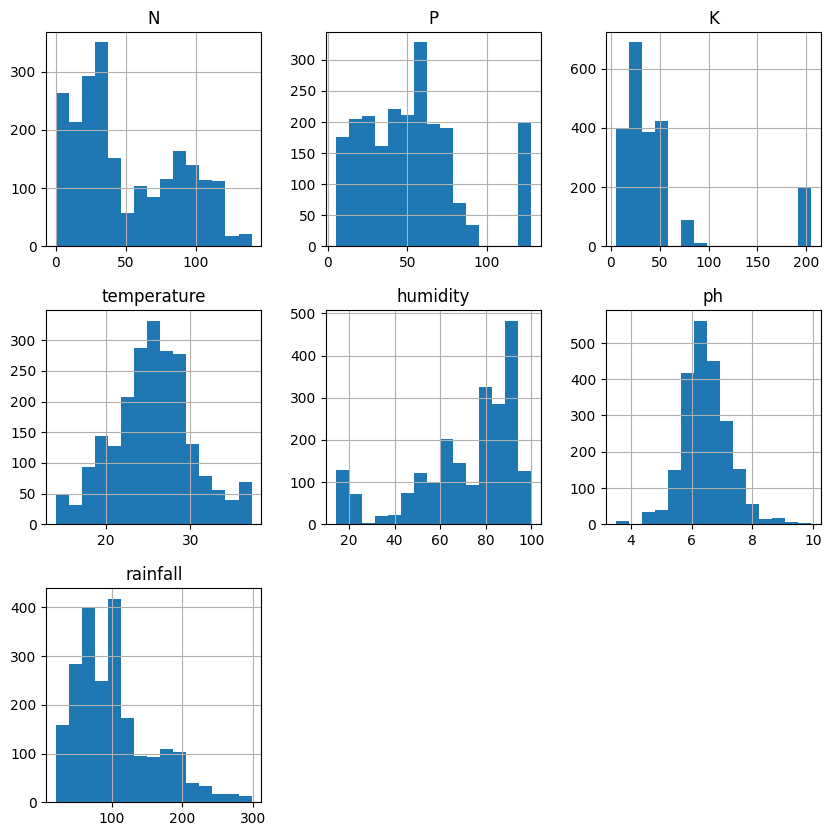

In [27]:
data.hist(bins=15, figsize=(10, 10))
plt.show()


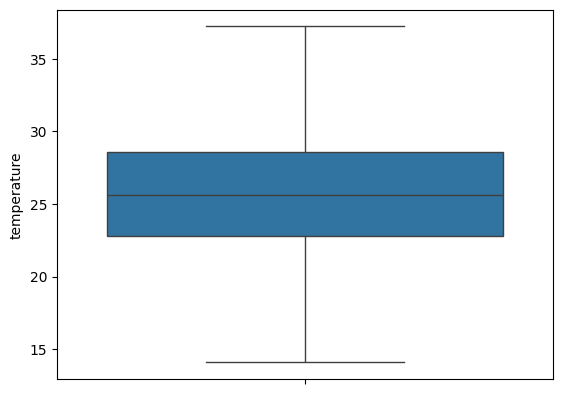

In [28]:
sns.boxplot(y="temperature", data=data)
plt.show()


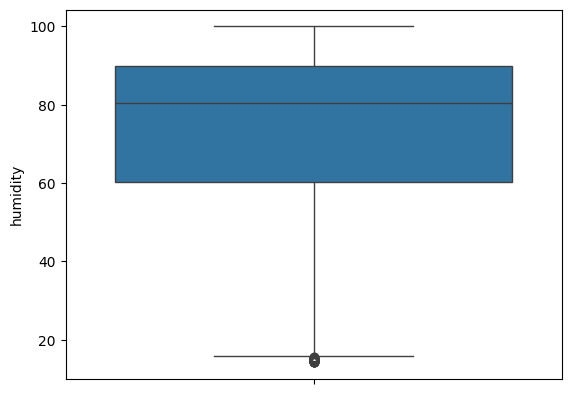

In [14]:
sns.boxplot(y="humidity", data=data)
plt.show()

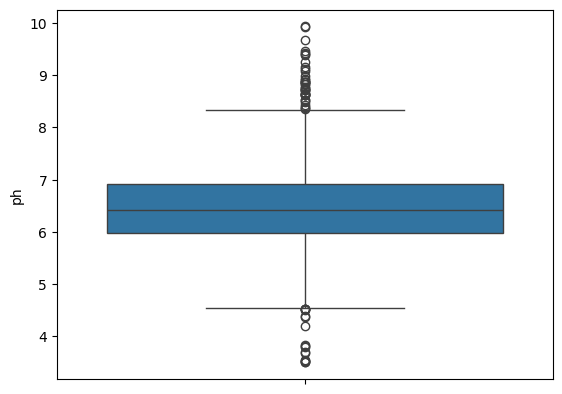

In [15]:
sns.boxplot(y="ph", data=data)
plt.show()


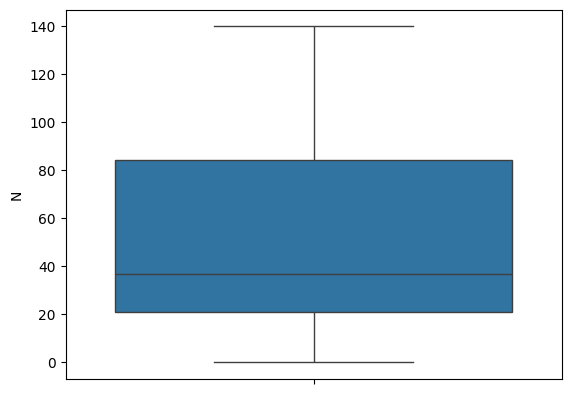

In [16]:
sns.boxplot(y="N", data=data)
plt.show()


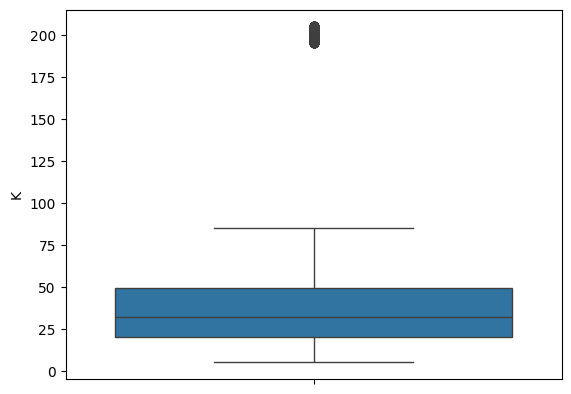

In [17]:
sns.boxplot(y="K", data=data)
plt.show()


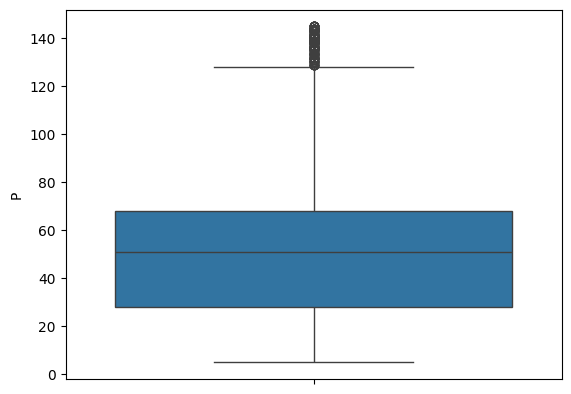

In [18]:
sns.boxplot(y="P", data=data)
plt.show()

## Remove the outliers

In [19]:
def remove_outliers(col_name):
    Q1, Q3 = col_name.quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lower_range = Q1 - (1.5 * IQR)
    upper_range = Q3 + (1.5 * IQR)
    return lower_range, upper_range

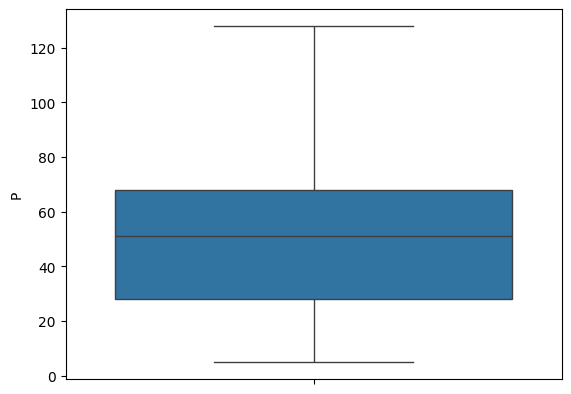

In [32]:
#Removing the Outlier of P

low, high = remove_outliers(data["P"])

data["P"] = np.where(
    data["P"] > high,
    high,
    np.where(data["P"] < low, low, data["P"])
)

sns.boxplot(y="P", data=data)
plt.show()

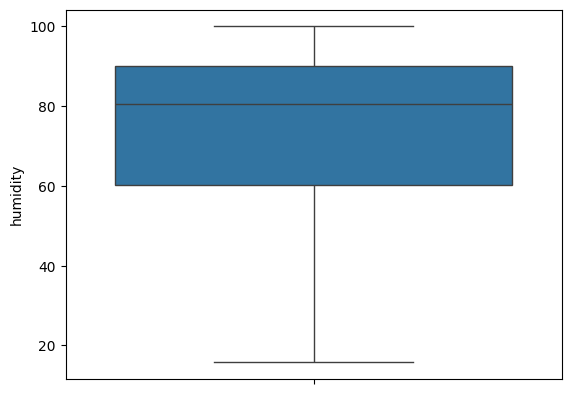

In [30]:
#Removing the Outlier of Humidity

low, high = remove_outliers(data["humidity"])

data["humidity"] = np.where(
    data["humidity"] > high,
    high,
    np.where(data["humidity"] < low, low, data["humidity"])

)

sns.boxplot(y="humidity", data=data)
plt.show()


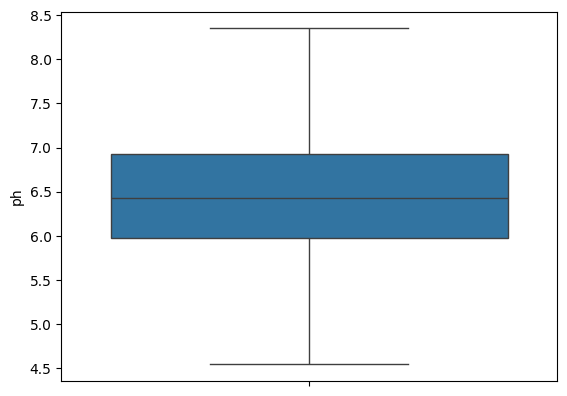

In [31]:
#Removing the Outlier of ph

low, high = remove_outliers(data["ph"])

data["ph"] = np.where(
    data["ph"] > high,
    high,
    np.where(data["ph"] < low, low, data["ph"])

)

sns.boxplot(y="ph", data=data)
plt.show()

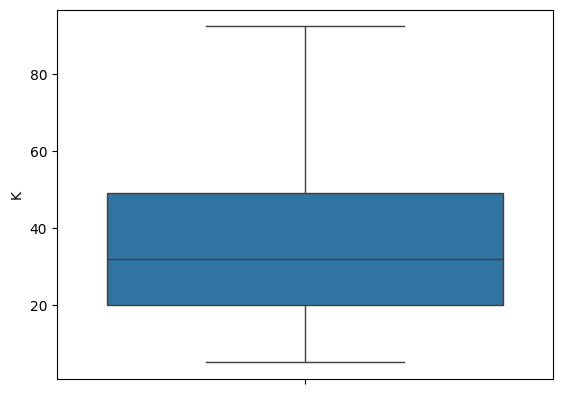

In [33]:
#Removing the Outlier of K

low, high = remove_outliers(data["K"])

data["K"] = np.where(
    data["K"] > high,
    high,
    np.where(data["K"] < low, low, data["K"])

)

sns.boxplot(y="K", data=data)
plt.show()

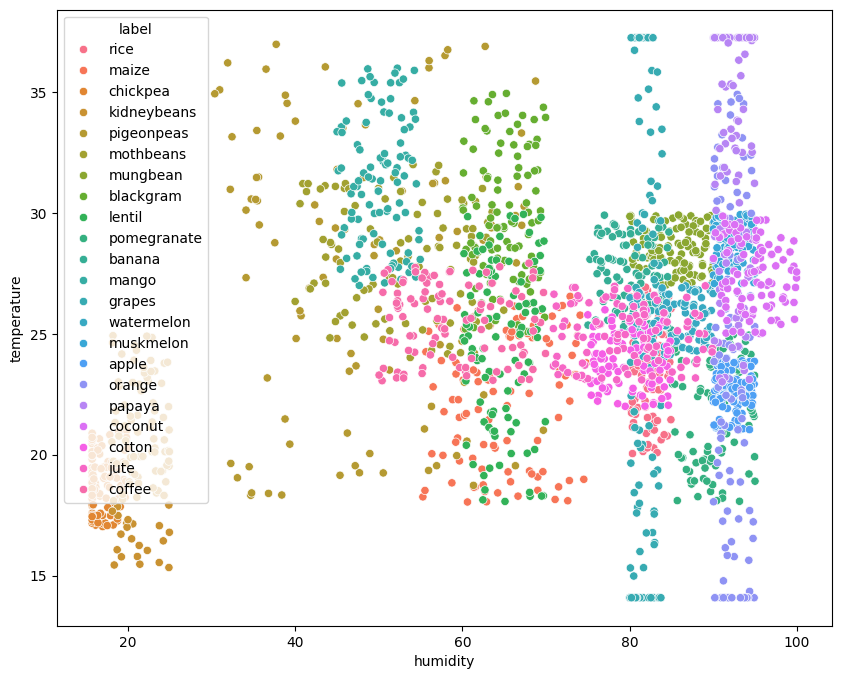

In [34]:
# Humidity vs Temperature
plt.figure(figsize=(10, 8))
sns.scatterplot(x="humidity", y="temperature", data=data, hue="label")
plt.show()

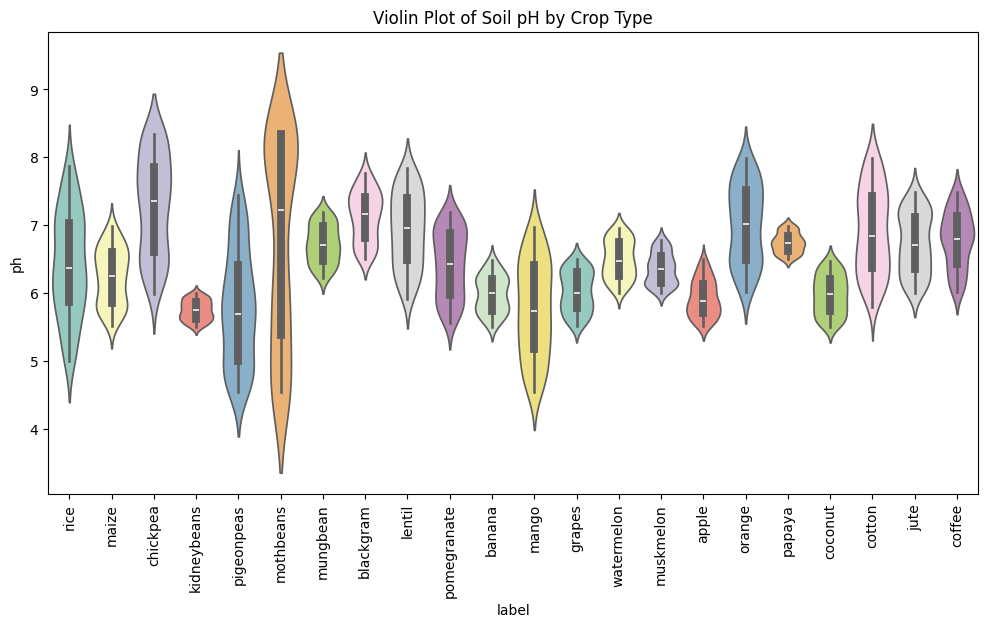

In [35]:
plt.figure(figsize=(12, 6))
sns.violinplot(
    x="label",
    y="ph",
    data=data,
    hue="label",
    palette="Set3",
    legend=False
)
plt.title("Violin Plot of Soil pH by Crop Type")
plt.xticks(rotation=90)
plt.show()

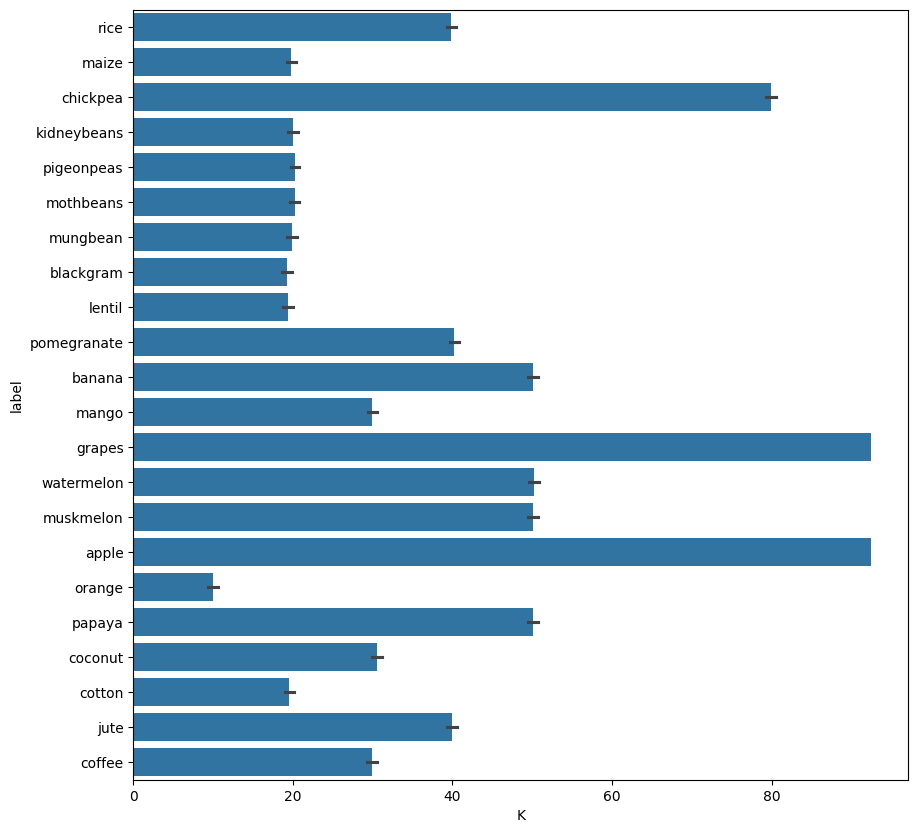

In [36]:
plt.figure(figsize=(10, 10))
sns.barplot(y="label", x="K", data=data)
plt.show()

In [37]:
data.groupby("label")["P"].mean().sort_values(ascending=False)

,P
label,
apple,126.66
grapes,126.46
banana,82.01
lentil,68.36
chickpea,67.79
pigeonpeas,67.73
kidneybeans,67.54
blackgram,67.47
papaya,59.05
